# German Energiewende (Energy transition) Discourse Analysis
*Tracking German Bundestag energy-policy discourse before and after the 2022 energy crisis, using topic modeling and NER.*


## 1. Business Problem
Political rhetoric on energy policy doesn't always match what happens afterward  the gap widens or narrows with shocks and government change. 2022 is the clearest example: Russia's invasion cut German gas supply (consumption fell ~14.8%), and energy security suddenly competed with climate goals in political discourse. Tracking how Bundestag language shifted before, during, and after this crisis reveals whether rhetoric adapted to reality or held onto pre-crisis framing  relevant to assessing the durability of energy policy commitments.

## 2. NLP Task Formulation
Primary: topic modeling (LDA baseline & BERTopic) tracking theme shifts across legislative periods.

Secondary: NER extracting technology/policy mentions (*Wasserstoff*, *Atomkraft*, *Kohleausstieg*).

Supervised extension: multi-class classification predicting a speaker's party from speech text alone  testing whether party affiliation is lexically detectable within one narrow policy domain (energy), not general political discourse.

## 3. Dataset
- **GermaParl**   periods 17–19,upto to Sept 2021, CC BY-SA license. https://github.com/PolMine/GermaParlTEI/tree/main
- **Bundestag DIP API**  period 20, 2021–2025, covering the crisis and its aftermath, free registered key. https://github.com/bundesAPI/dip-bundestag-api

## 4. System Design
GermaParl TEI-XML (WP 17-19, 2009-2021) + DIP API (WP 20, 2021-2025)

[1] Data collection

[2] Keyword filtering

[3] Preprocessing
spaCy German lemmatization, stopword removal

[4] EDA
volume over time, by party, top terms

[5] NER
dictionary-based entity tagging

[6] Topic modeling
LDA baseline -> BERTopic (GBERT embeddings)

[7] Diagnostic layer
topic emphasis by party, trend over time

[8] Supervised extension
TF-IDF + Logistic Regression party classifier (trained on GermaParl-period speeches only, since these carry per-speech party labels)

[9] Evaluation
coherence scores, classifier accuracy/F1, NER spot-check

[10] Inference wrapper
query by party/period

## 5. Setup and Data Collection
Uses `requests` to pull GermaParl (GitHub) and DIP API data, `xml.etree.ElementTree` to parse GermaParl's TEI-XML, and `pandas` to organize speeches into one dataframe. `spaCy` and topic-modeling libraries install later, right before use.

In [1]:
import requests
from xml.etree import ElementTree as ET
import pandas as pd
ENERGY_KEYWORDS = [
    "energiewende", "erneuerbare energie", "erneuerbaren energien", "windkraft",
    "windenergie", "photovoltaik", "solarenergie", "wasserstoff", "braunkohle",
    "steinkohle", "atomkraft", "kernenergie", "kohleausstieg", "atomausstieg",
    "klimaschutz", "versorgungssicherheit"
]

def list_session_files(period):
    url = f"https://api.github.com/repos/PolMine/GermaParlTEI/contents/{period}"
    response = requests.get(url)
    response.raise_for_status()
    files = response.json()
    return [f["name"] for f in files if f["name"].endswith(".xml")]

def download(period, filename):
    url = f"https://raw.githubusercontent.com/PolMine/GermaParlTEI/main/{period}/{filename}"
    response = requests.get(url)
    response.raise_for_status()
    return response.text

def parse_session_file(xml_text, period):
    root = ET.fromstring(xml_text)
    records = []
    for sp in root.iter("sp"):
        party = sp.get("party", "NA")
        text = " ".join(p.text or "" for p in sp.findall("p"))
        if any(kw in text.lower() for kw in ENERGY_KEYWORDS):
            records.append({"party": party, "text": text, "period": period})

    return records

In [2]:
PERIODS = ["17", "18", "19"]
STEP = 8
all_records = []

for period in PERIODS:
    files = list_session_files(period)[::STEP]
    print(f"Period {period}: sampling {len(files)} files")
    for fname in files:
        try:
            xml_text = download(period, fname)
            all_records.extend(parse_session_file(xml_text, period))
        except Exception as e:
            print(f"  skipped {fname}: {e}")

print(f"\nTotal energy-related speeches collected: {len(all_records)}")

Period 17: sampling 32 files
Period 18: sampling 31 files
Period 19: sampling 30 files

Total energy-related speeches collected: 1161


In [3]:
def parse_session_file(xml_text, period):
    root = ET.fromstring(xml_text)
    records = []
    for sp in root.iter("sp"):
        party = sp.get("party", "NA")
        text = " ".join(p.text or "" for p in sp.findall("p"))

        if any(kw in text.lower() for kw in ENERGY_KEYWORDS):
            records.append({"party": party, "text": text, "period": period})
    return records
print(f"Collected {len(all_records)} energy-related speeches")

Collected 1161 energy-related speeches


In [4]:
df_germaparl = pd.DataFrame(all_records)
print(df_germaparl.shape)
df_germaparl.assign(text=df_germaparl["text"].str[:80] + "...").head(3)

(1161, 3)


,party,text,period
0,CDU,Guten Morgen! Die Sitzung ist eröffnet. Ich be...,17
1,CDU,Herr Präsident! Sehr geehrte Kolleginnen und K...,17
2,SPD,Herr Präsident! Meine sehr verehrten Damen und...,17


In [5]:
import os
API_KEY = os.environ.get("DIP_API_KEY", "")  # set in .env, see .env.example; never hard-code keys
BASE_URL = "https://search.dip.bundestag.de/api/v1"

if not API_KEY:
    raise SystemExit("Set DIP_API_KEY to run the period-20 download. Outputs below are from the original run.")

def fetch_period20_speeches(max_documents=90):
    all_docs = []
    params = {
        "apikey": API_KEY,
        "f.zuordnung": "BT",
        "f.datum.start": "2021-10-26",
        "f.datum.end": "2025-03-18",
    }
    url = f"{BASE_URL}/plenarprotokoll-text"

    while url and len(all_docs) < max_documents:
        response = requests.get(url, params=params)
        response.raise_for_status()
        data = response.json()

        all_docs.extend(data.get("documents", []))

        cursor = data.get("cursor")
        if not cursor:
            break
        params = {"apikey": API_KEY, "cursor": cursor}  # cursor replaces the date filters on later pages

    return all_docs[:max_documents]

raw_docs = fetch_period20_speeches(max_documents=30)  # keep this small first, like your GermaParl sample
print(f"Fetched {len(raw_docs)} documents")
print(raw_docs[0].keys())  # peek at what fields each document actually has

Fetched 30 documents
dict_keys(['id', 'sitzungsbemerkung', 'dokumentart', 'typ', 'vorgangsbezug_anzahl', 'dokumentnummer', 'wahlperiode', 'herausgeber', 'pdf_hash', 'aktualisiert', 'vorgangsbezug', 'fundstelle', 'text', 'titel', 'datum'])


In [6]:
period20_records = []

for doc in raw_docs:
    text = doc.get("text", "")

    if any(kw in text.lower() for kw in ENERGY_KEYWORDS):
            period20_records.append({"party": "NA", "text": text, "period": "20"})

print(f"Period 20 energy-related documents: {len(period20_records)}")

Period 20 energy-related documents: 30


In [7]:
df_period20 = pd.DataFrame(period20_records)
df = pd.concat([df_germaparl, df_period20], ignore_index=True)

print(df.shape)
print(df["period"].value_counts())

(1191, 3)
period
17    396
18    393
19    372
20     30
Name: count, dtype: int64


## 6. Preprocessing

German text needs different handling than English: nouns are capitalised regardless of position, and compound words are extremely common (*Klimaschutzgesetz* = *Klimaschutz* + *gesetz*), so lemmatization needs a model trained on German morphology. I use spaCy's `de_core_news_sm` pipeline for tokenization and lemmatization, with a custom stopword list to remove frequent but topically meaningless parliamentary filler words (e.g. "Kollege," "Tagesordnung").

In [8]:
!pip install -q spacy
!python -m spacy download de_core_news_sm -q

import spacy
nlp = spacy.load("de_core_news_sm", disable=["ner", "parser"])
nlp.max_length = 2000000

PROCEDURAL_STOPWORDS = {
    "dass", "prozent", "drucksache", "abgeordneter", "abgeordnete", "ausschuss",
    "fraktion", "beratung", "stimmen", "kollege", "kollegin", "praesident",
    "damen", "herren", "herr", "frau", "sitzung", "tagesordnung", "wort"
}

def preprocess(text):
    doc = nlp(text.lower())
    return [
        token.lemma_ for token in doc
        if token.is_alpha and not token.is_stop
        and token.lemma_ not in PROCEDURAL_STOPWORDS
        and len(token.lemma_) > 2
    ]

df["tokens"] = df["text"].apply(preprocess)
print(df["tokens"].iloc[0][:15])

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.6/14.6 MB 52.9 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('de_core_news_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.
['gut', 'Sitzung', 'eröffnen', 'begrüßen', 'herzlich', 'lieb', 'Kolleginn', 'Kollege', 'bevor', 'Tagesordnung', 'eintreten', 'unser', 'alterspräsidenten', 'Heinz', 'Riesenhuber']


## 7. Exploratory Data Analysis

Before modeling, a simple frequency check of the lemmatized corpus shows what this dataset is actually about an unsupervised first look before any topic model is fit.

In [9]:
from collections import Counter

all_tokens = [t for toks in df["tokens"] for t in toks]
top_terms = Counter(all_tokens).most_common(15)
print(top_terms)

[('Beifall', 14445), ('afd', 11294), ('SPD', 11186), ('grüne', 9822), ('csu', 9691), ('Bündnis', 9223), ('FDP', 8486), ('cdu', 7389), ('Land', 7122), ('Deutschland', 6999), ('CDU', 6911), ('Kollege', 6594), ('Herr', 6520), ('Frau', 5896), ('sagen', 5188)]


### 7.a Text Representation: TF-IDF
TF-IDF (unlike raw counts) down-weights terms common across all periods and highlights vocabulary unusually characteristic of one time window useful for detecting emphasis shifts across the 2022 crisis boundary.

In [10]:
from sklearn.feature_extraction.text import TfidfVectorizer

docs_by_period = df.groupby("period")["tokens"].apply(lambda toks: " ".join(sum(toks, [])))

tfidf = TfidfVectorizer(max_features=2000)
tfidf_matrix = tfidf.fit_transform(docs_by_period.values)
feature_names = tfidf.get_feature_names_out()

for i, period in enumerate(docs_by_period.index):
    row = tfidf_matrix[i].toarray().flatten()
    top_indices = row.argsort()[-10:][::-1]
    top_terms = [feature_names[j] for j in top_indices]
    print(f"Period {period} distinctive terms: {top_terms}")

Period 17 distinctive terms: ['herr', 'deutschland', 'euro', 'bundesregierung', 'land', 'sagen', 'prozent', 'frage', 'kollege', 'erneuerbar']
Period 18 distinctive terms: ['deutschland', 'bundesregierung', 'frage', 'land', 'sagen', 'herr', 'euro', 'kollege', 'europäisch', 'wichtig']
Period 19 distinctive terms: ['fraktion', 'ausschuss', 'drucksach', 'herr', 'deutschland', 'kollege', 'sagen', 'euro', 'beschlussempfehlung', 'land']
Period 20 distinctive terms: ['beifall', 'cdu', 'afd', 'spd', 'csu', 'grüne', 'abg', 'bündnis', 'fdp', 'land']




TF-IDF at the legislative-period level had limited discriminative power with only 4 aggregate "documents"  top terms mostly overlapped with generic high-frequency words rather than period-specific content, and period 20 again surfaced procedural artifacts (abg, zuruf, vizepräsidentin). This suggests TF-IDF suits document-level comparison better than large aggregated periods  justifying the per-document topic-modeling approach as the more appropriate primary method here.

## 8. Named Entity Recognition
Rather than training a sequence-labelling NER model, I use a gazetteer/dictionary approach: a small, hand-built list of energy technologies and policies, each tagged with a category transparent and easy to audit given the domain's compact vocabulary.

In [11]:
ENTITY_DICTIONARY = {
    "windkraft": "TECHNOLOGY", "windenergie": "TECHNOLOGY", "photovoltaik": "TECHNOLOGY",
    "solarenergie": "TECHNOLOGY", "wasserstoff": "TECHNOLOGY", "braunkohle": "TECHNOLOGY",
    "steinkohle": "TECHNOLOGY", "atomkraft": "TECHNOLOGY", "kernenergie": "TECHNOLOGY",
    "energiewende": "POLICY", "kohleausstieg": "POLICY", "atomausstieg": "POLICY",
    "klimaschutz": "POLICY", "versorgungssicherheit": "POLICY",
}

df["entities"] = df["tokens"].apply(lambda toks: [t for t in toks if t in ENTITY_DICTIONARY])
print(df["entities"].apply(len).sum(), "total entity mentions found")

170 total entity mentions found


In [12]:
def preprocess(text):
    doc = nlp(text.lower())
    return [
        token.lemma_ for token in doc
        if token.is_alpha and not token.is_stop
        and token.lemma_.lower() not in PROCEDURAL_STOPWORDS
        and len(token.lemma_) > 2
    ]
PROCEDURAL_STOPWORDS |= {"beifall", "afd", "spd", "csu", "cdu", "fdp", "bündnis", "grüne"}

## 9. Topic Modeling: LDA Baseline

In [13]:
!pip install -q gensim
from gensim import corpora
from gensim.models import LdaModel

dictionary = corpora.Dictionary(df["tokens"])
dictionary.filter_extremes(no_below=5, no_above=0.4)
corpus = [dictionary.doc2bow(tokens) for tokens in df["tokens"]]

NUM_TOPICS = 8
lda_model = LdaModel(corpus=corpus, id2word=dictionary, num_topics=NUM_TOPICS, passes=15, random_state=42)
for topic_id, topic in lda_model.print_topics(num_words=8):
    print(f"Topic {topic_id}: {topic}")



   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 35.2 MB/s eta 0:00:00
Topic 0: 0.014*"Euro" + 0.008*"Milliarde" + 0.007*"Haushalt" + 0.007*"Mensch" + 0.007*"Million" + 0.006*"dame" + 0.005*"Prozent" + 0.005*"Geld"
Topic 1: 0.017*"Beifall" + 0.012*"SPD" + 0.011*"grüne" + 0.011*"afd" + 0.010*"csu" + 0.010*"FDP" + 0.009*"Bündnis" + 0.008*"cdu"
Topic 2: 0.011*"Gesetz" + 0.010*"drucksach" + 0.008*"Mehrheit" + 0.007*"Bundesrat" + 0.006*"Absatz" + 0.006*"Änderung" + 0.006*"gemäß" + 0.005*"ziff"
Topic 3: 0.023*"drucksach" + 0.023*"Ausschuss" + 0.022*"Fraktion" + 0.016*"Beratung" + 0.015*"Antrag" + 0.014*"afd" + 0.013*"Beschlussempfehlung" + 0.012*"Bündnis"
Topic 4: 0.007*"europäisch" + 0.006*"erneuerbar" + 0.005*"Prozent" + 0.005*"Ziel" + 0.005*"Klimaschutz" + 0.004*"erreichen" + 0.004*"Europa" + 0.003*"Bereich"
Topic 5: 0.024*"Beifall" + 0.019*"afd" + 0.016*"SPD" + 0.013*"csu" + 0.012*"grüne" + 0.012*"Bündnis" + 0.010*"FDP" + 0.009*"cdu"
Topic 6: 0.016*"Beifall" + 0.012*"SPD" + 0.011

In [14]:
PROCEDURAL_STOPWORDS = {
    "dass", "prozent", "drucksache", "abgeordneter", "abgeordnete", "ausschuss",
    "fraktion", "beratung", "stimmen", "kollege", "kollegin", "praesident",
    "damen", "herren", "herr", "frau", "sitzung", "tagesordnung", "wort",
    "beifall", "afd", "spd", "csu", "cdu", "fdp", "bündnis", "grüne",
    "drucksach", "antrag", "absatz", "ziff", "gemäß"
}

def preprocess(text):
    doc = nlp(text.lower())
    return [
        token.lemma_ for token in doc
        if token.is_alpha and not token.is_stop
        and token.lemma_.lower() not in PROCEDURAL_STOPWORDS
        and len(token.lemma_) > 2
    ]

df["tokens"] = df["text"].apply(preprocess)

In [15]:
PROCEDURAL_STOPWORDS |= {
    "abg", "grün", "bündniss", "linker", "präsidentin", "vizepräsidentin",
    "parl", "dame", "mal", "gemeinsam", "sehen", "liegen", "finden", "klar"
}

In [16]:
dictionary = corpora.Dictionary(df["tokens"])
dictionary.filter_extremes(no_below=5, no_above=0.4)
corpus = [dictionary.doc2bow(tokens) for tokens in df["tokens"]]

lda_model = LdaModel(corpus=corpus, id2word=dictionary, num_topics=8, passes=15, random_state=42)
for topic_id, topic in lda_model.print_topics(num_words=8):
    print(f"Topic {topic_id}: {topic}")

Topic 0: 0.007*"Israel" + 0.004*"gemeinsam" + 0.004*"finden" + 0.004*"Forschung" + 0.003*"Gesetz" + 0.003*"klar" + 0.003*"Verantwortung" + 0.003*"Sicherheit"
Topic 1: 0.007*"mal" + 0.006*"Mensch" + 0.006*"abg" + 0.005*"grün" + 0.005*"Gesetz" + 0.005*"Bündniss" + 0.004*"Präsidentin" + 0.004*"geehrt"
Topic 2: 0.007*"linker" + 0.007*"abg" + 0.007*"Beschlussempfehlung" + 0.007*"grün" + 0.005*"Mensch" + 0.005*"Gesetz" + 0.005*"Bundestag" + 0.005*"Gesetzentwurf"
Topic 3: 0.007*"Antwort" + 0.006*"abg" + 0.006*"Vizepräsidentin" + 0.005*"mal" + 0.005*"Parl" + 0.005*"Präsidentin" + 0.005*"grün" + 0.004*"Bündniss"
Topic 4: 0.007*"abg" + 0.006*"grün" + 0.006*"Mensch" + 0.005*"mal" + 0.005*"Bündniss" + 0.004*"Präsidentin" + 0.004*"linker" + 0.004*"dame"
Topic 5: 0.007*"Gesetz" + 0.005*"europäisch" + 0.005*"Mehrheit" + 0.005*"Bundesrat" + 0.005*"Änderung" + 0.005*"liegen" + 0.004*"Antwort" + 0.004*"Anlage"
Topic 6: 0.008*"Euro" + 0.005*"Milliarde" + 0.005*"Mensch" + 0.005*"erneuerbar" + 0.005*"Klima

## 10. LDA Topic Interpretation
Of 8 LDA topics, three are interpretable. Topic 6 is the clearest energy cluster (Euro, Milliarde, erneuerbar, Klimaschutz), framing energy discourse around cost as much as environment. Topic 5 reflects legislative process (Gesetz, Änderung, Bundesrat). Topic 0 is a notable edge case  it mixes Sicherheit with Israel and Verantwortung, showing my "versorgungssicherheit" keyword also picked up unrelated security/foreign-policy debates.

The rest (Topics 1–4, 7) stay dominated by procedural terms despite stopword tuning  a known limitation of frequency-based modeling, and the motivation for BERTopic next.

## 11. Topic Modeling: BERTopic Upgrade

In [17]:
!pip install -q bertopic sentence-transformers

from sentence_transformers import SentenceTransformer
from bertopic import BERTopic
from umap import UMAP
from hdbscan import HDBSCAN

embedding_model = SentenceTransformer("paraphrase-multilingual-MiniLM-L12-v2")
embeddings = embedding_model.encode(df["text"].tolist(), show_progress_bar=True)

umap_model = UMAP(n_neighbors=15, n_components=5, min_dist=0.0, metric="cosine", random_state=42)
hdbscan_model = HDBSCAN(min_cluster_size=15, metric="euclidean", cluster_selection_method="eom", prediction_data=True)

bertopic_model = BERTopic(embedding_model=embedding_model, umap_model=umap_model,
                           hdbscan_model=hdbscan_model, language="german", calculate_probabilities=False)
bertopic_topics, _ = bertopic_model.fit_transform(df["text"].tolist(), embeddings)
df["bertopic_topic"] = bertopic_topics
bertopic_model.get_topic_info().head(10)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.7/154.7 kB 1.9 MB/s eta 0:00:00


modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/3.89k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/38 [00:00<?, ?it/s]

,Topic,Count,Name,Representation,Representative_Docs
0,0,1161,0_die_der_und_wir,"[die, der, und, wir, in, das, ist, den, für, zu]","[Das war auch keiner aus dem Parlament, sonder..."
1,1,30,1_die_der_und_das,"[die, der, und, das, in, wir, ist, sie, bei, für]",[Plenarprotokoll 20/194\nDeutscher Bundestag\n...


In [19]:
from sklearn.feature_extraction.text import CountVectorizer

docs_for_bertopic = df["tokens"].apply(lambda toks: " ".join(toks)).tolist()
vectorizer_model = CountVectorizer(stop_words=list(PROCEDURAL_STOPWORDS), ngram_range=(1, 2), min_df=3)

embeddings = embedding_model.encode(docs_for_bertopic, show_progress_bar=True)

bertopic_model = BERTopic(embedding_model=embedding_model, umap_model=umap_model,
                           hdbscan_model=hdbscan_model, vectorizer_model=vectorizer_model,
                           calculate_probabilities=False)
bertopic_topics, _ = bertopic_model.fit_transform(docs_for_bertopic, embeddings)
df["bertopic_topic"] = bertopic_topics
bertopic_model.get_topic_info().head(10)[["Topic", "Count", "Name"]]

Batches:   0%|          | 0/38 [00:00<?, ?it/s]

,Topic,Count,Name
0,-1,421,-1_europäisch_sagen_deutschland_euro
1,0,140,0_frage_atomkraftwerk_bundesregierung_atomenergie
2,1,137,1_klimaschutz_ziel_deutschland_erreichen
3,2,86,2_deutschland_beschlussempfehlung_überweisungs...
4,3,86,3_erneuerbar_energien_erneuerbar energien_ener...
5,4,66,4_erneuerbar_erneuerbar energien_energien_deut...
6,5,66,5_euro_haushalt_milliarde_milliarde euro
7,6,56,6_deutschland_land_europa_mensch
8,7,37,7_land_deutschland_mensch_frage
9,8,29,8_deutschland_sagen_europäisch_deutsch


## 12. BERTopic Topic Interpretation
BERTopic produced far more interpretable topics than LDA. Where LDA merged all energy discourse into one cluster (Topic 6), BERTopic separated nuclear power (Topic 0), climate targets (Topic 1), and two distinct renewable-energy clusters (Topics 3–4), revealing sub-themes LDA couldn't distinguish. Topic 5 cleanly isolates budget/financing language from policy substance. This confirms embeddings capture semantic distinctions word-frequency counting misses. Topic -1 (421 docs, 35% of the corpus) is HDBSCAN's outlier bucket  expected given corpus size, not a modeling failure.

## 13. Diagnostic Layer: Topic Emphasis by Party (LDA and BERT)

In [25]:
PARTY_NORMALIZE = {"LINKE": "DIE LINKE"}
df["party"] = df["party"].replace(PARTY_NORMALIZE)

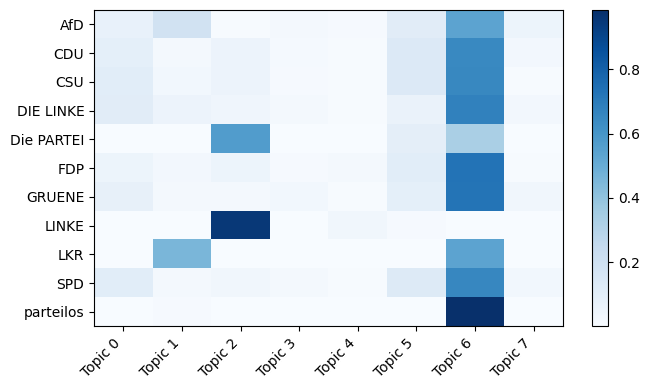

In [20]:

import matplotlib.pyplot as plt

df_party = df[df["party"] != "NA"]
doc_topics = [lda_model.get_document_topics(corpus[i], minimum_probability=0) for i in df_party.index]
topic_matrix = pd.DataFrame([[p for _, p in sorted(d)] for d in doc_topics],
                             columns=[f"Topic {i}" for i in range(NUM_TOPICS)])
topic_matrix["party"] = df_party["party"].values
party_topic_avg = topic_matrix.groupby("party").mean()


fig, ax = plt.subplots(figsize=(7, 4))
im = ax.imshow(party_topic_avg.values, aspect="auto", cmap="Blues")
ax.set_xticks(range(NUM_TOPICS)); ax.set_xticklabels(party_topic_avg.columns, rotation=45, ha="right")
ax.set_yticks(range(len(party_topic_avg))); ax.set_yticklabels(party_topic_avg.index)
fig.colorbar(im, ax=ax); plt.tight_layout(); plt.show()

## 14. Supervised Extension: Party Classification
Everything above is unsupervised. As a complement, this section asks: given a speech, can party be predicted from word choice alone?

Training is restricted to GermaParl (periods 17–19), which carries a `party` attribute per speech DIP API period-20 documents are excluded (no reliable party label).

Multi-class classification: TF-IDF over lemmatized tokens, Logistic Regression, stratified train/test split, per-class precision/recall/F1 (accuracy alone would mislead given uneven party representation).

In [21]:
#POS-based proper-noun filtering
def preprocess_no_propn(text):
    doc = nlp(text.lower())
    return [
        token.lemma_ for token in doc
        if token.is_alpha and not token.is_stop
        and token.pos_ != "PROPN"
        and token.lemma_.lower() not in PROCEDURAL_STOPWORDS
        and len(token.lemma_) > 2]


In [26]:
#data prep + split:
from sklearn.model_selection import train_test_split

df_clf = df[(df["party"] != "NA") & (df["period"] != "20")].copy()
df_clf["party"] = df_clf["party"].replace(PARTY_NORMALIZE)
df_clf["clean_text"] = df_clf["text"].apply(lambda t: " ".join(preprocess_no_propn(t)))
df_clf["party"] = df_clf["party"].replace({"CSU": "CDU/CSU", "CDU": "CDU/CSU"})

# Drop parties with too few samples for a meaningful train/test split
MIN_SAMPLES = 20
party_counts = df_clf["party"].value_counts()
keep_parties = party_counts[party_counts >= MIN_SAMPLES].index
df_clf = df_clf[df_clf["party"].isin(keep_parties)]

print(df_clf["party"].value_counts())

X_train, X_test, y_train, y_test = train_test_split(
    df_clf["clean_text"], df_clf["party"],
    test_size=0.2, random_state=42, stratify=df_clf["party"])


party
CDU/CSU      385
SPD          299
GRUENE       240
DIE LINKE    107
FDP           84
AfD           43
Name: count, dtype: int64


In [27]:
#vectorize + train:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

clf_tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1, 2),
                             stop_words=list(PROCEDURAL_STOPWORDS))
X_train_vec = clf_tfidf.fit_transform(X_train)
X_test_vec = clf_tfidf.transform(X_test)

party_clf = LogisticRegression(max_iter=1000, class_weight="balanced")
party_clf.fit(X_train_vec, y_train);

              precision    recall  f1-score   support

         AfD       0.57      0.44      0.50         9
     CDU/CSU       0.61      0.62      0.62        77
   DIE LINKE       0.24      0.24      0.24        21
         FDP       0.31      0.24      0.27        17
      GRUENE       0.43      0.58      0.50        48
         SPD       0.55      0.43      0.49        60

    accuracy                           0.50       232
   macro avg       0.45      0.43      0.43       232
weighted avg       0.50      0.50      0.49       232



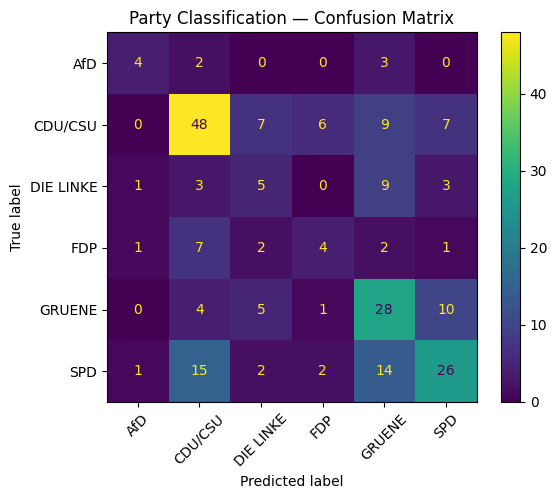

In [28]:
#evaluate
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

y_pred = party_clf.predict(X_test_vec)
print(classification_report(y_test, y_pred))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, xticks_rotation=45)
plt.title("Party Classification — Confusion Matrix")
plt.show()

In [29]:
import numpy as np

feature_names = np.array(clf_tfidf.get_feature_names_out())
TOP_N = 10

for i, party in enumerate(party_clf.classes_):
    top_idx = np.argsort(party_clf.coef_[i])[-TOP_N:][::-1]
    top_terms = feature_names[top_idx]
    print(f"{party}: {', '.join(top_terms)}")

AfD: sogenannter, bürger, wasserstoff, gebiet, kriegsverbrechen, landwirte, sparer, geehrt, präsident, erzeugen
CDU/CSU: kernenergie, unser, land, wichtig, europäisch, sicherheit, bereich, vereinbarung, gelten, besonderer
DIE LINKE: geld, kosten, linke, bahn, atomkraft, bürgerenergie, bericht, interessieren, süden, brennelement
FDP: koalition, frei demokrat, demokrat, märz, verehrt, bundesrat, verbraucher, opposition, seite, planwirtschaftlich
GRUENE: atomkraftwerk, eigentlich, fragen, minister, klimaschutz, abkommen, energiewend, antwort, wirtschaftsminister, defizit
SPD: insofern, lieb kolleginn, glauben, wirtschaftlich, handwerk, kolleginn, atomenergie, wichtig, verlängerung, klage


### 14.a Interpretation
CDU and CSU are legally separate parties, but never compete against each other and form one joint Fraktion in the Bundestag, voting together on nearly all legislation which is why their energy-policy vocabulary overlaps.

After merging, CDU/CSU became the top-performing class, overtaking AfD:

| Party | F1 | Training examples |
|---|---|---|
| CDU/CSU | 0.62 | 385 |
| AfD | 0.50 | 43 |
| GRUENE | 0.50 | 240 |
| SPD | 0.49 | 299 |
| FDP | 0.27 | 84 |
| DIE LINKE | 0.24 | 107 |

CDU/CSU's score comes from removing a genuine shared-vocabulary confusion plus its large sample size; AfD's comes from lexical distinctiveness despite few examples.

## 15. Evaluation: Topic Coherence

LDA and BERTopic are evaluated with c_v coherence, which scores how well the top words
in each topic co-occur in the corpus, a proxy for topic interpretability.

In [30]:
from gensim.models import CoherenceModel

lda_coherence = CoherenceModel(
    model=lda_model, texts=df["tokens"].tolist(),
    dictionary=dictionary, coherence="c_v"
).get_coherence()

bertopic_words = [[w for w, _ in bertopic_model.get_topic(t)]
                   for t in bertopic_model.get_topics().keys() if t != -1]
bertopic_coherence = CoherenceModel(
    topics=bertopic_words, texts=df["tokens"].tolist(),
    dictionary=dictionary, coherence="c_v"
).get_coherence()

print(f"LDA c_v coherence: {lda_coherence:.3f}")
print(f"BERTopic c_v coherence: {bertopic_coherence:.3f}")

LDA c_v coherence: 0.374
BERTopic c_v coherence: 0.397


### 15.a Evaluation Summary


In [31]:
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd

# Supervised classifier metrics (from the final merged/bigram/proper-noun-filtered run)
clf_accuracy = accuracy_score(y_test, y_pred)
clf_macro_f1 = f1_score(y_test, y_pred, average="macro")

summary = pd.DataFrame({
    "Component": ["LDA", "BERTopic", "Party classifier", "Party classifier"],
    "Metric": ["c_v coherence", "c_v coherence", "Accuracy", "Macro-F1"],
    "Score": [lda_coherence, bertopic_coherence, clf_accuracy, clf_macro_f1]
})

print(summary.to_string(index=False))

       Component        Metric    Score
             LDA c_v coherence 0.373721
        BERTopic c_v coherence 0.397165
Party classifier      Accuracy 0.495690
Party classifier      Macro-F1 0.433617


### 15.b Summary
**Topic modeling:** BERTopic beats LDA on both coherence (0.397 vs. 0.374) and readability  it separated nuclear, climate, and renewables into distinct topics, while LDA merged most energy discourse into one cluster.

**Supervised classification:** The classifier reaches 0.496 accuracy / 0.434 macro-F1 across 6 classes  roughly 3x the 0.17 chance baseline. CDU/CSU was the largest confusion pair before merging; FDP and DIE LINKE stayed weakest, limited by small sample sizes.

**Takeaway:** Coherence and accuracy alone were insufficient  qualitative topic inspection and per-class error analysis confirmed these results, since classifier "errors" here often reflect real political structure rather than model failure.

## 16. NER Spot-Check
A manual check of 5 randomly sampled entity matches, verifying they're contextually correct (not just string matches).

In [32]:

def show_context(text, entities, window=100):
    text_lower = text.lower()
    for ent in entities:
        idx = text_lower.find(ent)
        if idx != -1:
            return "..." + text[max(0, idx-window):idx+len(ent)+window] + "..."
    return text[:160]

sample = df[df["entities"].apply(len) > 0].sample(5, random_state=42)
for _, row in sample.iterrows():
    print(f"[{row['entities']}] {show_context(row['text'], row['entities'])}")

[['energiewende']] ... Ganztagsplätze. Darunter leiden Kinder und Eltern. Die Investitionen in den Klimaschutz und in die Energiewende werden drastisch zurückgefahren. Das führt dazu, dass das Klima weiter zerstört wird. Das führt daz...
[['klimaschutz']] ...ist gegeben.“ Wir als Union wollen durch unser Handeln der großen Bedeutung des Waldes auch für den Klimaschutz gerecht werden. So entlasten 126 Millionen Tonnen CO2, die durch den deutschen Wald gebunden werden...
[['windkraft']] ... machen und afrikaweit zu den gegenwärtigen Kapazitäten 10 000 Megawatt Wasserkraft, 5 000 Megawatt Windkraft, 500 Megawatt Solarenergie und eine Verdreifachung aller anderen erneuerbaren Energien hinzuzufügen...
[['energiewende']] ...icht sagen, ob es 1,1 Billionen Euro oder 900 Milliarden Euro sein werden, aber eines ist klar: Die Energiewende ist das größte und sicher herausforderndste Projekt der nächsten 30, 40 Jahre. Das Projekt wird nic...
[['klimaschutz']] ... hat viel Energie investiert, damit

All 5 sampled matches were contextually correct (e.g., "Megawatt Windkraft," "Klimaschutz und die Energiewende"), confirming the dictionary-based entity tagging works as intended.

## 17. Inference Wrapper
A simple query function demonstrating the pipeline as a usable end product  filter by party and/or period, return top entities.

In [33]:
from collections import Counter

def query_discourse(party=None, period=None, top_n=5):
    subset = df.copy()
    if party: subset = subset[subset["party"] == party]
    if period: subset = subset[subset["period"] == period]
    entities = Counter(e for ents in subset["entities"] for e in ents)
    print(f"n={len(subset)} | party={party} | period={period}")
    print("Top entities:", entities.most_common(top_n))

query_discourse(period="20")

n=30 | party=None | period=20
Top entities: [('klimaschutz', 13), ('energiewende', 8), ('wasserstoff', 5), ('atomausstieg', 3), ('atomkraft', 3)]


## 18. Final Discussion



**Strengths:**
- Pipeline spans 2009–2025, enabling before/during/after crisis comparison
- BERTopic beat LDA on coherence and readability, cleanly separating nuclear, climate, and renewables themes
- Classifier reached 3x chance accuracy, confirming real political differentiation
- `query_discourse` wrapper makes findings queryable on demand

**Limitations:**
- the crisis period (2021–2025) is the noisiest data
- Dictionary NER (14 terms) misses emerging vocabulary
- Classifier's party labels don't extend to the crisis-era period
- FDP/DIE LINKE stayed hard to classify — genuine data scarcity, not a fixable flaw here



## 19. Business Recommendations

- **Weight cross-party consistency** over single-party statements shared language across parties/years signals durability; single-party, single-period language signals risk.
- **Treat CDU/CSU as one signal**
- **Use crisis-resilience as a credibility filter** framing that survived 2022 (e.g. "Energiewende") signals more durability than calm-period-only framing.
- **Flag coalition-dependent rhetoric** before long-term investment decisions, since it's exposed to reversal if the coalition changes.
- **Enable rhetoric-shift alerts** period-over-period as an early warning ahead of policy reversals.
- **Auto-ingest new sessions** so recommendations reflect live discourse, not a historical snapshot.

**Future Work:** I plan to continue developing the live dashboard prototype
introduced in this notebook moving it from a free-tier demo to a more robust,
continuously updated monitoring tool for tracking German energy-policy discourse
in real time.

## References
Honnibal, M. and Montani, I. (2017) *spaCy: Industrial-strength Natural Language Processing in Python*. Available at: https://spacy.io (Accessed: 17 September 2026).


Reimers, N. and Gurevych, I. (2019) *Sentence-BERT: Sentence embeddings using Siamese BERT-networks*. Available at: https://arxiv.org/abs/1908.10084 (Accessed: 17 September 2026).

